# When is 90% not 90%?
## Understanding the Clopper-Pearson exact binomial confidence interval

**DigitalSreeni** | Python and AI for scientists

A player makes 9 of 10 free throws. Another makes 90 of 100. A third makes 900 of 1,000.
All three shot exactly 90%. Do we know the same amount about all three?

**Roadmap:** the 90% problem, sample size, Stephen Curry, what a confidence interval means, one-sided versus two-sided bounds,
how Clopper-Pearson works, and a real malaria cell classifier.

**Central message:** an observed percentage is not the same thing as the underlying probability. Sample size matters.

---
# 0. Setup

The first cell checks the required packages. Sections 1 to 8 need only NumPy, Pandas, SciPy, and Matplotlib; Section 9 also uses scikit-learn and Pillow.
`ipywidgets` is optional (sliders in Section 7).

In [ ]:
import importlib

# import name -> pip install name
REQUIRED = {
    "numpy": "numpy",
    "pandas": "pandas",
    "scipy": "scipy",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
    "PIL": "pillow",
}
OPTIONAL = {"ipywidgets": "ipywidgets"}

missing = []
for import_name, pip_name in {**REQUIRED, **OPTIONAL}.items():
    try:
        module = importlib.import_module(import_name)
        version = getattr(module, "__version__", "installed")
        print(f"  [ok]      {pip_name:<14} {version}")
    except ImportError:
        tag = "optional" if import_name in OPTIONAL else "MISSING"
        print(f"  [{tag}] {pip_name}")
        if import_name in REQUIRED:
            missing.append(pip_name)

if missing:
    print("\nInstall the missing packages with:\n  pip install " + " ".join(missing))
else:
    print("\nAll required packages are available.")

  [ok]      numpy          2.4.6
  [ok]      pandas         2.2.3
  [ok]      scipy          1.16.3
  [ok]      matplotlib     3.10.0
  [ok]      scikit-learn   1.6.1
  [ok]      pillow         11.3.0
  [ok]      ipywidgets     7.7.1

All required packages are available.


Next: imports, a consistent plotting style, and a fixed random seed so every simulation and data split is reproducible.
Colors are used consistently: **teal** for the larger sample (or an interval that captures the truth), **amber** for the smaller sample (or a miss).

In [ ]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from scipy.stats import beta, binom
from IPython.display import display

SEED = 42
rng = np.random.default_rng(SEED)

# Consistent, restrained color palette (DigitalSreeni)
NAVY = "#0C2B45"        # text, reference lines
TEAL = "#0F6E56"        # large sample / interval contains the truth
LIGHT_TEAL = "#5DCAA5"  # bands and fills
AMBER = "#D97706"       # small sample / interval misses the truth
GRAY = "#8A97A6"        # secondary elements
N_RAMP = ["#9ED9C6", "#3FA585", "#0F6E56"]  # light to dark teal for n = 10, 100, 1000

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlecolor": NAVY,
    "axes.labelcolor": NAVY,
    "axes.edgecolor": GRAY,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#E3E8EE",
    "grid.linewidth": 0.8,
    "xtick.color": NAVY,
    "ytick.color": NAVY,
    "legend.frameon": False,
    "figure.dpi": 110,
    "figure.facecolor": "white",
})

pd.set_option("display.precision", 4)
print("Setup complete. Random seed:", SEED)

Setup complete. Random seed: 42


Finally, one helper function, `clopper_pearson(k, n)`, that we use throughout. Treat it as a black box for now; we open it in **Section 6**.
Every number in this notebook is calculated by it; nothing is typed in by hand.

In [ ]:
def clopper_pearson(k, n, confidence=0.95):
    # Exact (Clopper-Pearson) binomial confidence bounds for k successes in n trials.
    #
    # Returns a dict with:
    #   observed   : k / n
    #   lower_1s   : one-sided lower confidence bound at `confidence`
    #   lower_2s   : lower end of the two-sided interval at `confidence`
    #   upper_2s   : upper end of the two-sided interval at `confidence`

    # ---- input validation ----
    if isinstance(k, bool) or isinstance(n, bool):
        raise TypeError("k and n must be integers, not booleans.")
    if not (float(k).is_integer() and float(n).is_integer()):
        raise TypeError(f"k and n must be whole numbers (got k={k}, n={n}).")
    k, n = int(k), int(n)
    if n <= 0:
        raise ValueError("n must be at least 1: a proportion is undefined with zero trials.")
    if not 0 <= k <= n:
        raise ValueError(f"k must satisfy 0 <= k <= n (got k={k}, n={n}).")
    if not 0 < confidence < 1:
        raise ValueError("confidence must be between 0 and 1, for example 0.95.")

    alpha = 1 - confidence

    # One-sided lower bound: all of alpha goes into the lower tail.
    lower_1s = 0.0 if k == 0 else beta.ppf(alpha, k, n - k + 1)

    # Two-sided interval: alpha / 2 in each tail.
    lower_2s = 0.0 if k == 0 else beta.ppf(alpha / 2, k, n - k + 1)
    upper_2s = 1.0 if k == n else beta.ppf(1 - alpha / 2, k + 1, n - k)

    return {
        "k": k,
        "n": n,
        "observed": k / n,
        "lower_1s": float(lower_1s),
        "lower_2s": float(lower_2s),
        "upper_2s": float(upper_2s),
    }


def cp_table(cases, confidence=0.95):
    # Build a tidy table of Clopper-Pearson results for a list of (label, k, n).
    rows = []
    for label, k, n in cases:
        r = clopper_pearson(k, n, confidence)
        rows.append({
            "Case": label,
            "Successes (k)": r["k"],
            "Attempts (n)": r["n"],
            "Observed": r["observed"],
            "One-sided 95% lower bound": r["lower_1s"],
            "Two-sided 95% CI lower": r["lower_2s"],
            "Two-sided 95% CI upper": r["upper_2s"],
            "Two-sided CI width": r["upper_2s"] - r["lower_2s"],
        })
    return pd.DataFrame(rows).set_index("Case")


def as_percent(df):
    # Display helper: show proportions as percentages with one decimal place.
    pct_cols = [c for c in df.columns if c not in ("Successes (k)", "Attempts (n)")]
    return df.style.format({c: "{:.1%}" for c in pct_cols})

---
# 1. The 90% problem

A player takes 10 free throws and makes 9. Is this a **90% free-throw shooter**? Would you bet on 9 of the next 10?

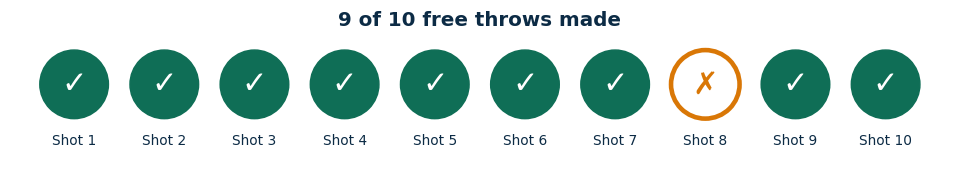

In [ ]:
def plot_shots(outcomes, title):
    # Draw one circle per shot: filled teal for a make, open amber for a miss.
    n = len(outcomes)
    fig, ax = plt.subplots(figsize=(1.0 * n + 1, 2.0))
    for i, made in enumerate(outcomes):
        if made:
            ax.add_patch(Circle((i, 0), 0.38, color=TEAL))
            ax.text(i, 0, "✓", ha="center", va="center", color="white", fontsize=20, weight="bold")
        else:
            ax.add_patch(Circle((i, 0), 0.38, facecolor="white", edgecolor=AMBER, linewidth=3))
            ax.text(i, 0, "✗", ha="center", va="center", color=AMBER, fontsize=20, weight="bold")
        ax.text(i, -0.62, f"Shot {i + 1}", ha="center", va="center", color=NAVY, fontsize=9)
    ax.set_xlim(-0.7, n - 0.3)
    ax.set_ylim(-0.85, 0.55)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title)
    plt.show()


shots = [1, 1, 1, 1, 1, 1, 1, 0, 1, 1]   # 9 makes, 1 miss
k_shots, n_shots = sum(shots), len(shots)
plot_shots(shots, f"{k_shots} of {n_shots} free throws made")

The natural summary is the **observed proportion**:

$$
\hat{p} = \frac{k}{n} = \frac{\text{successes}}{\text{attempts}}
$$

In [ ]:
p_hat = k_shots / n_shots
print(f"k = {k_shots}, n = {n_shots}")
print(f"Observed success rate p_hat = {k_shots}/{n_shots} = {p_hat:.1%}")

k = 9, n = 10
Observed success rate p_hat = 9/10 = 90.0%


Keep three things separate:

- **Observed proportion** $\hat{p}$: what happened in this sample (9 of 10). We know it.
- **True probability** $p$: the player's long-run success rate. We never see it directly.
- **Uncertainty**: how far $\hat{p}$ could plausibly be from $p$. This is what we want to quantify.

With only 10 shots, luck plays a large role: a genuine 75% shooter makes 9 or more of 10 about one time in four.
So "90%" here is a fact about the sample, not a reliable statement about the player.

---
# 2. The role of sample size

Three players, all at exactly 90%: 9/10, 90/100, and 900/1000. The percentage is identical; the **amount of evidence** is not.
For each, we compute the **two-sided 95% confidence interval** (a range of plausible values for the true probability)
and the **one-sided 95% lower bound** (a conservative minimum; explained in Section 5).

In [ ]:
scenarios = [
    ("9 / 10", 9, 10),
    ("90 / 100", 90, 100),
    ("900 / 1000", 900, 1000),
]
scenario_table = cp_table(scenarios)
as_percent(scenario_table)

,Successes (k),Attempts (n),Observed,One-sided 95% lower bound,Two-sided 95% CI lower,Two-sided 95% CI upper,Two-sided CI width
Case,,,,,,,
9 / 10,9,10,90.0%,60.6%,55.5%,99.7%,44.2%
90 / 100,90,100,90.0%,83.6%,82.4%,95.1%,12.7%
900 / 1000,900,1000,90.0%,88.3%,88.0%,91.8%,3.8%


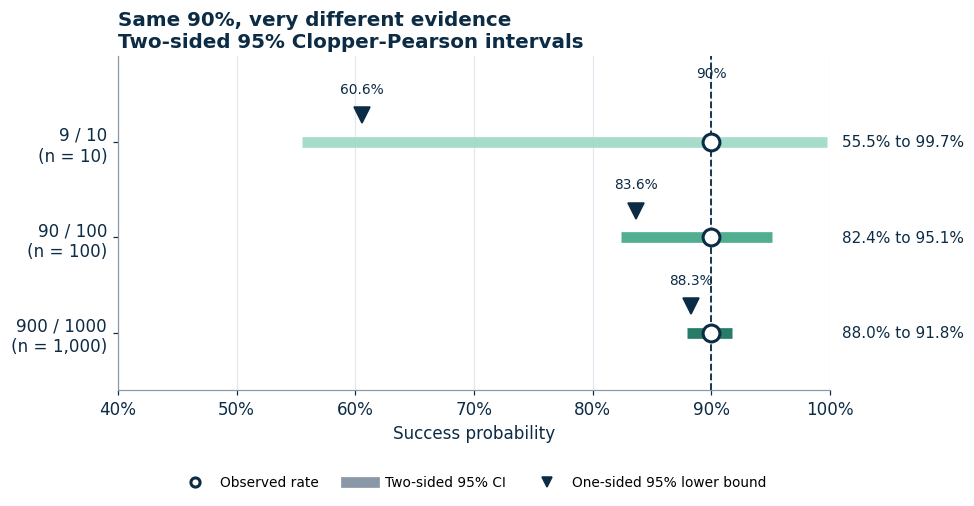

In [ ]:
def plot_intervals(table, colors, title, xlim=(0.4, 1.0), ref_line=None, ref_label=None):
    # Forest-style plot: one row per case with observed rate, two-sided CI, and one-sided lower bound.
    fig, ax = plt.subplots(figsize=(9, 0.9 * len(table) + 2.2))
    y_positions = np.arange(len(table))[::-1]
    for y, (label, row), color in zip(y_positions, table.iterrows(), colors):
        ax.hlines(y, row["Two-sided 95% CI lower"], row["Two-sided 95% CI upper"],
                  color=color, linewidth=7, alpha=0.9, capstyle="butt")
        ax.plot(row["Observed"], y, "o", color="white", markersize=11, markeredgecolor=NAVY, markeredgewidth=2, zorder=3)
        ax.plot(row["One-sided 95% lower bound"], y + 0.28, marker="v", color=NAVY, markersize=10, zorder=3)
        ax.text(row["One-sided 95% lower bound"], y + 0.48, f"{row['One-sided 95% lower bound']:.1%}",
                ha="center", va="bottom", fontsize=9, color=NAVY)
        ax.text(xlim[1] + 0.01, y,
                f"{row['Two-sided 95% CI lower']:.1%} to {row['Two-sided 95% CI upper']:.1%}",
                va="center", fontsize=10, color=NAVY)
    if ref_line is not None:
        ax.axvline(ref_line, color=NAVY, linestyle="--", linewidth=1.2)
        if ref_label:
            ax.text(ref_line, len(table) - 0.35, ref_label, ha="center", va="bottom", fontsize=9, color=NAVY)
    ax.set_yticks(y_positions)
    ax.set_yticklabels([f"{lab}\n(n = {int(r['Attempts (n)']):,})" for lab, r in table.iterrows()])
    ax.set_xlim(*xlim)
    ax.set_ylim(-0.6, len(table) - 0.1)
    decimals = 1 if (xlim[1] - xlim[0]) < 0.25 else 0   # finer tick labels on narrow ranges
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.{decimals}%}"))
    ax.set_xlabel("Success probability")
    ax.grid(axis="y", visible=False)
    ax.set_title(title, loc="left")
    # small legend explaining the marks
    ax.plot([], [], "o", color="white", markeredgecolor=NAVY, markeredgewidth=2, label="Observed rate")
    ax.plot([], [], color=GRAY, linewidth=7, label="Two-sided 95% CI")
    ax.plot([], [], "v", color=NAVY, label="One-sided 95% lower bound")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3, fontsize=9)
    plt.tight_layout()
    plt.show()


plot_intervals(scenario_table, N_RAMP,
               "Same 90%, very different evidence\nTwo-sided 95% Clopper-Pearson intervals",
               ref_line=0.9, ref_label="90%")

In the chart, the **dot** is the observed 90%, the **bar** is the two-sided 95% interval, and the **triangle** is the one-sided 95% lower bound.

- **10 attempts:** the true probability could be anywhere from the mid 50s to the high 90s.
- **1,000 attempts:** the interval hugs 90% closely.

Same percentage, very different evidence. The width shrinks roughly with $1/\sqrt{n}$: to halve the uncertainty you need about four times the data.

---
# 3. Stephen Curry: one spectacular game versus a full season

On **November 7, 2016**, against the New Orleans Pelicans, Stephen Curry made **13 three-pointers on 17 attempts** (76.5%) and scored **46 points**,
setting the NBA single-game record for three-pointers at the time. Over the **2016-17 regular season** he made **324 of 789** (41.1%).

These figures were checked against independent sources, and all agree:

- NBA.com, Golden State Warriors: https://www.nba.com/warriors/news-blogs/stephen-curry-warriors-classics-20200320
- AP game report (Star Tribune): https://www.startribune.com/warriors-curry-sets-nba-record-with-13-three-pointers/400359951
- Sports Illustrated: https://www.si.com/nba/2016/11/08/stephen-curry-golden-state-warriors-nba-three-point-record
- StatMuse game log (13 3PM, 17 3PA, 46 PTS): https://www.statmuse.com/nba/ask/steph-curry-highest-3s
- StatMuse 2016-17 totals (324 of 789): https://www.statmuse.com/nba/ask/steph-3-pointers-in-2017
- Land of Basketball 2016-17: https://www.landofbasketball.com/nba_players_season_stats/2017/stephen_curry_full.htm

What does one spectacular game tell us about his underlying shooting probability, compared with a full season?

In [ ]:
# Verified statistics (see sources above)
CURRY_GAME_MADE, CURRY_GAME_ATT = 13, 17        # Nov 7, 2016 vs New Orleans
CURRY_SEASON_MADE, CURRY_SEASON_ATT = 324, 789  # 2016-17 regular season

curry_table = cp_table([
    ("Single game (Nov 7, 2016)", CURRY_GAME_MADE, CURRY_GAME_ATT),
    ("2016-17 regular season", CURRY_SEASON_MADE, CURRY_SEASON_ATT),
])
as_percent(curry_table)

,Successes (k),Attempts (n),Observed,One-sided 95% lower bound,Two-sided 95% CI lower,Two-sided 95% CI upper,Two-sided CI width
Case,,,,,,,
"Single game (Nov 7, 2016)",13,17,76.5%,53.9%,50.1%,93.2%,43.1%
2016-17 regular season,324,789,41.1%,38.1%,37.6%,44.6%,7.0%


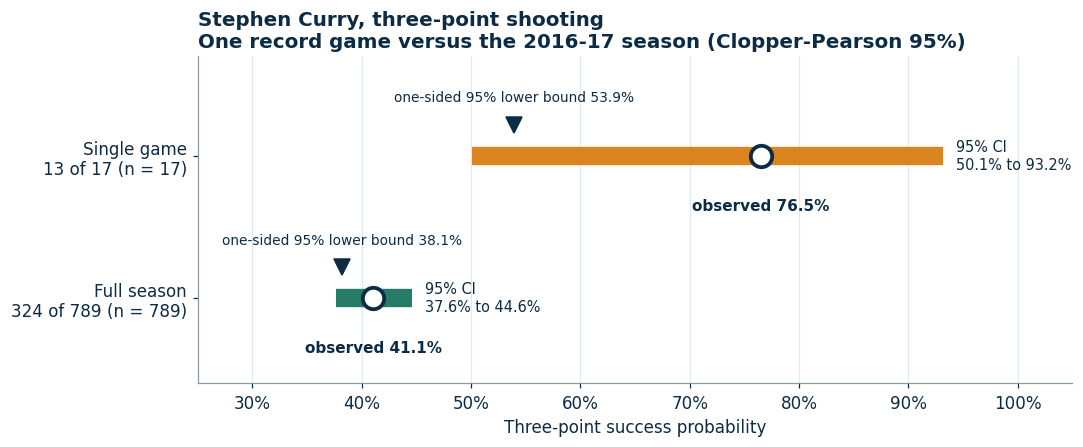

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.2))
rows_to_plot = curry_table.iloc[:2]
colors = [AMBER, TEAL]
y_pos = [1, 0]
for y, (label, row), color in zip(y_pos, rows_to_plot.iterrows(), colors):
    lo, hi, obs, lb = row["Two-sided 95% CI lower"], row["Two-sided 95% CI upper"], row["Observed"], row["One-sided 95% lower bound"]
    ax.hlines(y, lo, hi, color=color, linewidth=12, capstyle="butt", alpha=0.9)
    ax.plot(obs, y, "o", color="white", markeredgecolor=NAVY, markeredgewidth=2.5, markersize=14, zorder=3)
    ax.plot(lb, y + 0.22, "v", color=NAVY, markersize=11, zorder=3)
    ax.text(obs, y - 0.3, f"observed {obs:.1%}", ha="center", va="top", fontsize=10, color=NAVY, weight="bold")
    ax.text(lb, y + 0.36, f"one-sided 95% lower bound {lb:.1%}", ha="center", va="bottom", fontsize=9, color=NAVY)
    ax.text(hi + 0.012, y, f"95% CI\n{lo:.1%} to {hi:.1%}", va="center", fontsize=9.5, color=NAVY)

ax.set_yticks(y_pos)
ax.set_yticklabels([
    f"Single game\n{CURRY_GAME_MADE} of {CURRY_GAME_ATT} (n = {CURRY_GAME_ATT})",
    f"Full season\n{CURRY_SEASON_MADE} of {CURRY_SEASON_ATT} (n = {CURRY_SEASON_ATT})",
])
ax.set_xlim(0.25, 1.05)
ax.set_ylim(-0.6, 1.7)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Three-point success probability")
ax.grid(axis="y", visible=False)
ax.set_title("Stephen Curry, three-point shooting\nOne record game versus the 2016-17 season (Clopper-Pearson 95%)", loc="left")
plt.tight_layout()
plt.show()

**What we see:**

- The **single-game** interval (17 attempts) spans more than 40 percentage points. 76.5% is spectacular, but 17 shots cannot pin down a shooting probability.
- The **season** interval (789 attempts) is about 7 points wide.

Notice that the season rate lies **outside** the single-game interval. That is not a failure of the method: we did not pick a random game,
we picked his **most extreme** game. An interval's guarantee applies to data collected before seeing the result, not to the best result selected afterwards.
Scientists know this as selection bias, or cherry-picking.

**Caveat:** basketball shots are not identical, independent coin flips; distance, defense, and fatigue all vary.
This example illustrates **sampling uncertainty**, not a complete model of a player's ability.

---
# 4. What is a confidence interval?

A **point estimate** is one number ("90%"). An **interval estimate** is a range ("55.5% to 99.7%") that puts the uncertainty on display.

What does **95% confidence** mean?

> If we repeated the same experiment many times and calculated an interval each time,
> about 95% of those intervals would contain the true probability.

The 95% describes the **method**, not one particular interval. Once computed, a specific interval either contains the truth or it does not;
we only know the procedure succeeds at least 95% of the time in the long run.

Let us **see** this. We pretend we know the truth ($p = 0.90$), run 200 experiments of $n = 10$ shots and 200 of $n = 100$ shots,
compute a two-sided 95% interval for each, and color it by whether it contains the truth.

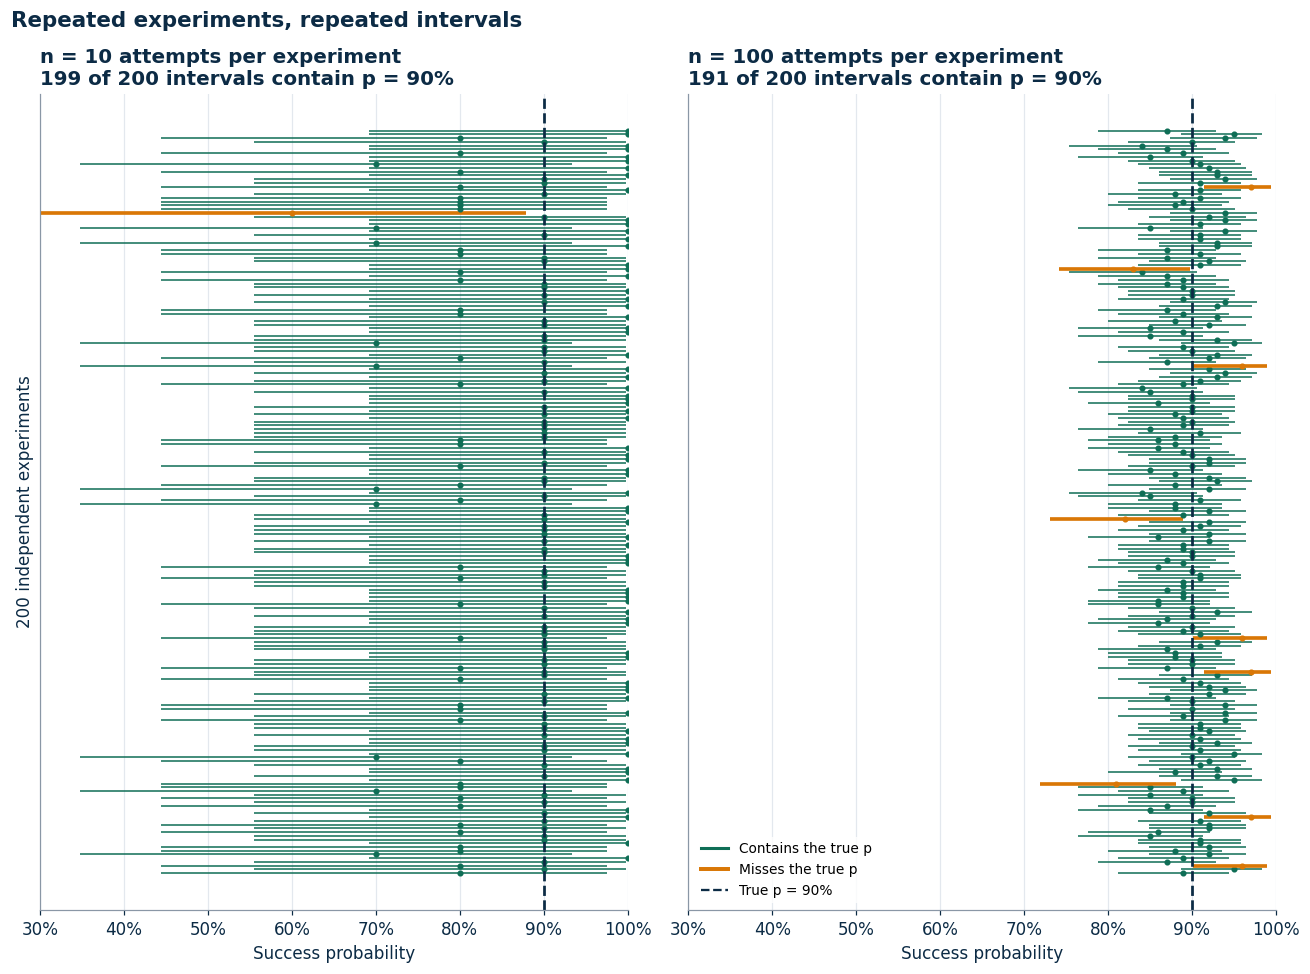

 n = 10: 100% of intervals contain the truth, average width 42.1%
n = 100: 96% of intervals contain the truth, average width 12.6%


In [ ]:
def simulate_intervals(p_true, n, n_experiments, seed):
    # Run n_experiments binomial experiments of size n and return a DataFrame of Clopper-Pearson intervals.
    sim_rng = np.random.default_rng(seed)
    k_values = sim_rng.binomial(n, p_true, size=n_experiments)
    results = pd.DataFrame([clopper_pearson(k, n) for k in k_values])
    results["contains_truth"] = (results["lower_2s"] <= p_true) & (p_true <= results["upper_2s"])
    return results


def plot_repeated_intervals(ax, results, p_true, n):
    # Draw one vertical-stacked horizontal line per experiment, colored by whether it captures p_true.
    for i, row in results.iterrows():
        color = TEAL if row["contains_truth"] else AMBER
        lw = 1.0 if row["contains_truth"] else 2.4
        ax.hlines(i, row["lower_2s"], row["upper_2s"], color=color, linewidth=lw)
        ax.plot(row["observed"], i, "o", color=color, markersize=3)
    ax.axvline(p_true, color=NAVY, linewidth=1.8, linestyle="--")
    captured = results["contains_truth"].sum()
    ax.set_title(f"n = {n} attempts per experiment\n{captured} of {len(results)} intervals contain p = {p_true:.0%}", loc="left")
    ax.set_xlim(0.3, 1.0)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_xlabel("Success probability")
    ax.set_yticks([])
    ax.grid(axis="y", visible=False)


P_TRUE = 0.90
N_EXPERIMENTS = 200
sim_small = simulate_intervals(P_TRUE, n=10, n_experiments=N_EXPERIMENTS, seed=SEED)
sim_large = simulate_intervals(P_TRUE, n=100, n_experiments=N_EXPERIMENTS, seed=SEED + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 9), sharey=True)
plot_repeated_intervals(axes[0], sim_small, P_TRUE, 10)
plot_repeated_intervals(axes[1], sim_large, P_TRUE, 100)
axes[0].set_ylabel(f"{N_EXPERIMENTS} independent experiments")
axes[1].plot([], [], color=TEAL, linewidth=2, label="Contains the true p")
axes[1].plot([], [], color=AMBER, linewidth=2.6, label="Misses the true p")
axes[1].plot([], [], color=NAVY, linestyle="--", label="True p = 90%")
axes[1].legend(loc="lower left", fontsize=9, frameon=True, facecolor="white", edgecolor="none")
fig.suptitle("Repeated experiments, repeated intervals", x=0.01, ha="left", fontsize=14, weight="bold", color=NAVY)
plt.tight_layout()
plt.show()

for name, sim in (("n = 10", sim_small), ("n = 100", sim_large)):
    width = (sim["upper_2s"] - sim["lower_2s"]).mean()
    print(f"{name:>7}: {sim['contains_truth'].mean():.0%} of intervals contain the truth, average width {width:.1%}")

**What the simulation shows:**

- Each line is one experiment's interval; the dashed line is the truth, which in real life we never see.
- Most intervals capture the truth; the amber ones miss. Occasional misses are part of the deal.
- With **n = 10** the intervals are wide and jump around. With **n = 100** they are much narrower and still capture the truth about 95% of the time or more.

In the $n = 10$ panel you may see few or no misses: Clopper-Pearson is deliberately **conservative**, so its actual coverage is often above 95% (Section 6).

---
# 5. One-sided versus two-sided confidence intervals

| Interval | Question it answers | How the 5% error is spent |
|---|---|---|
| **Two-sided 95% CI** | Where is the true probability, plausibly? | 2.5% below, 2.5% above |
| **One-sided 95% lower bound** | What is the **minimum** plausible true probability? | All 5% below |

In science we often care about **minimum performance**: the minimum plausible sensitivity of a diagnostic test, whether a classifier clears a required threshold,
or a conservative estimate of a treatment or assay success rate. Nobody worries that a test is "too good". That is why this tutorial focuses on the **one-sided 95% lower bound**.

Here are both for Curry's 13 of 17.

In [ ]:
r95 = clopper_pearson(CURRY_GAME_MADE, CURRY_GAME_ATT, confidence=0.95)

lower_bound_table = pd.DataFrame({
    "Quantity": [
        "Observed rate",
        "One-sided 95% lower bound (5% in lower tail)",
        "Two-sided 95% CI lower end (2.5% in lower tail)",
        "Two-sided 95% CI upper end (2.5% in upper tail)",
    ],
    "Value": [r95["observed"], r95["lower_1s"], r95["lower_2s"], r95["upper_2s"]],
}).set_index("Quantity")
lower_bound_table.style.format({"Value": "{:.2%}"})

,Value
Quantity,
Observed rate,76.47%
One-sided 95% lower bound (5% in lower tail),53.95%
Two-sided 95% CI lower end (2.5% in lower tail),50.10%
Two-sided 95% CI upper end (2.5% in upper tail),93.19%


> A one-sided 95% lower confidence bound is **not** the same as the lower endpoint of a two-sided 95% confidence interval.

Because the one-sided bound spends all 5% on the lower side, it is always **higher**. Mixing them up either understates or overstates your result.

**Where do the bounds come from?** For each candidate true probability $p$, ask: "If the truth were $p$, how likely is a result **at least as good** as 13 of 17?"
For small $p$ that chance is tiny. The lower bound is the $p$ at which the chance rises to 5% (one-sided) or 2.5% (two-sided).

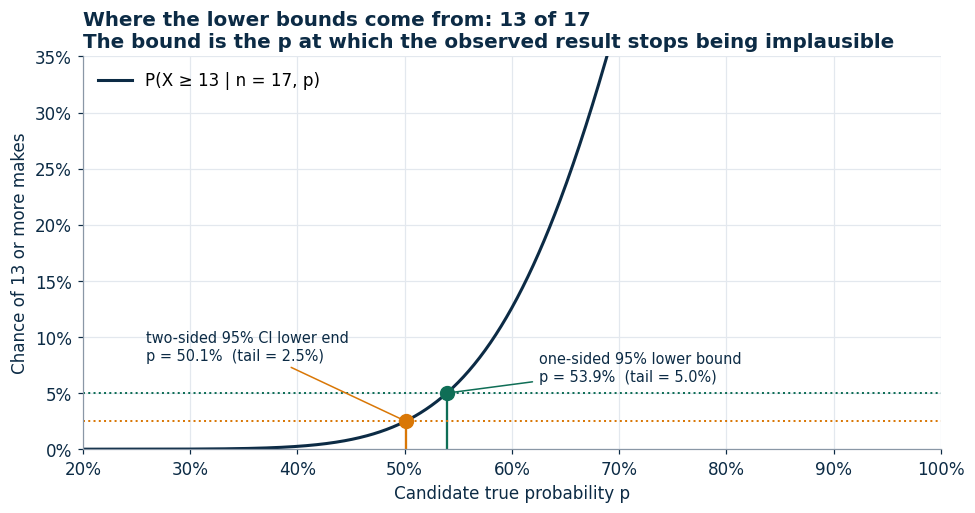

In [ ]:
k, n = CURRY_GAME_MADE, CURRY_GAME_ATT
p_grid = np.linspace(0.2, 1.0, 801)
tail_prob = binom.sf(k - 1, n, p_grid)   # P(X >= k | n, p)

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(p_grid, tail_prob, color=NAVY, linewidth=2, label=f"P(X ≥ {k} | n = {n}, p)")
for level, bound, color, name in (
    (0.05, r95["lower_1s"], TEAL, "one-sided 95% lower bound"),
    (0.025, r95["lower_2s"], AMBER, "two-sided 95% CI lower end"),
):
    ax.axhline(level, color=color, linestyle=":", linewidth=1.3)
    ax.plot(bound, level, "o", color=color, markersize=9, zorder=3)
    ax.vlines(bound, 0, level, color=color, linewidth=1.5)
    ax.annotate(f"{name}\np = {bound:.1%}  (tail = {level:.1%})", (bound, level),
                xytext=(-170, 40) if level == 0.025 else (60, 8),
                textcoords="offset points", fontsize=9.5, color=NAVY,
                arrowprops=dict(arrowstyle="-", color=color))
ax.set_xlim(0.2, 1.0)
ax.set_ylim(0, 0.35)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Candidate true probability p")
ax.set_ylabel(f"Chance of {k} or more makes")
ax.set_title(f"Where the lower bounds come from: {k} of {n}\nThe bound is the p at which the observed result stops being implausible", loc="left")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

Values of $p$ left of a dot would make 13 of 17 too unlikely, so they are ruled out. The one-sided bound uses the looser 5% threshold, so it sits higher.
This "rule out every $p$ that makes the data too surprising" logic **is** the Clopper-Pearson method.

---
# 6. Inside the Clopper-Pearson method

Clopper and Pearson (1934) start from the **binomial** model: $n$ independent trials, each a success or failure with the same probability $p$, and $k$ observed successes.

The curve in Section 5 was $P(X \ge k \mid n, p)$. The lower bound $p_L$ solves

$$
P(X \ge k \mid n, p_L) = \alpha
$$

with $\alpha = 0.05$ for a one-sided 95% bound (or $0.025$ for the two-sided lower end). The two-sided upper bound solves $P(X \le k \mid n, p_U) = 0.025$.

### Why the beta distribution appears

The **beta distribution** describes a quantity between 0 and 1, such as a probability. Its two shape parameters behave roughly like counts of successes and failures:
more total counts make it narrower. An exact identity links it to the binomial tail:

$$
P(X \ge k \mid n, p) = F_{\text{Beta}(k,\; n-k+1)}(p)
$$

So the curve we plotted **is** a beta cumulative distribution function (CDF). Finding the $p$ where that CDF reaches $\alpha$ is just asking for a **quantile**.
The function that returns quantiles is the **quantile function** (inverse CDF), which SciPy calls the **percent point function**, `ppf`.

The figure shows the beta distribution behind each of our three 90% results.

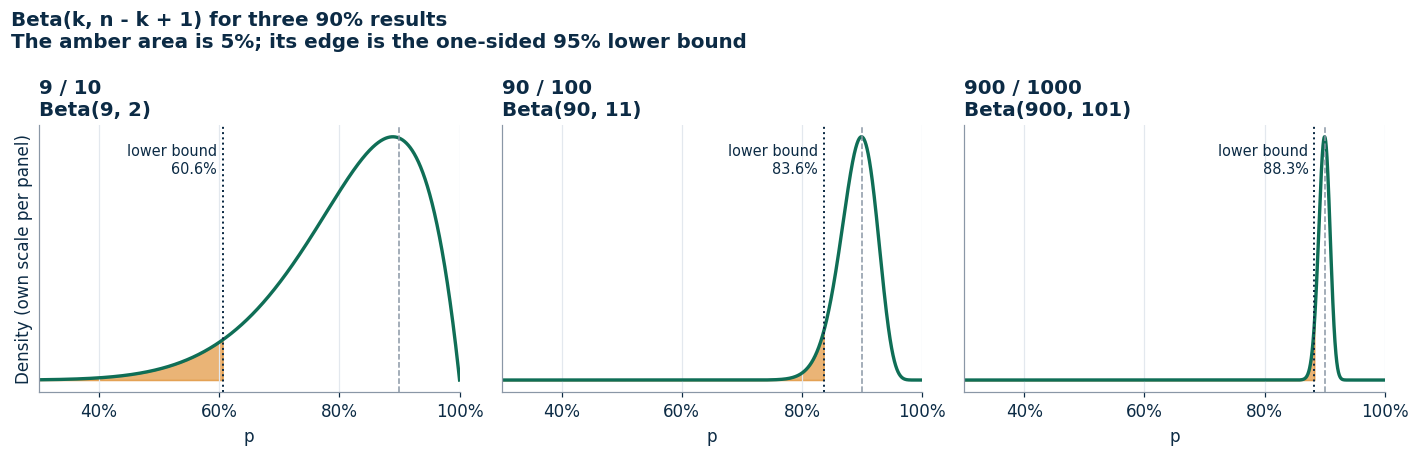

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
x = np.linspace(0.3, 1.0, 3000)
for ax, (label, k_b, n_b), color in zip(axes, scenarios, N_RAMP[::-1][::-1]):
    a_shape, b_shape = k_b, n_b - k_b + 1
    density = beta.pdf(x, a_shape, b_shape)
    lb = beta.ppf(0.05, a_shape, b_shape)          # one-sided 95% lower bound
    ax.plot(x, density, color=TEAL, linewidth=2.2)
    tail = x <= lb
    ax.fill_between(x[tail], density[tail], color=AMBER, alpha=0.55, label="5% of the area")
    ax.axvline(lb, color=NAVY, linestyle=":", linewidth=1.3)
    ax.axvline(0.9, color=GRAY, linestyle="--", linewidth=1)
    ax.text(lb - 0.01, density.max() * 0.85, f"lower bound\n{lb:.1%}", ha="right", fontsize=9.5, color=NAVY)
    ax.set_title(f"{label}\nBeta({a_shape}, {b_shape})", loc="left")
    ax.set_xlim(0.3, 1.0)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_xlabel("p")
    ax.set_yticks([])
    ax.set_xticks([0.4, 0.6, 0.8, 1.0])
axes[0].set_ylabel("Density (own scale per panel)")
fig.suptitle("Beta(k, n - k + 1) for three 90% results\nThe amber area is 5%; its edge is the one-sided 95% lower bound",
             x=0.01, ha="left", fontsize=13, weight="bold", color=NAVY)
plt.tight_layout()
plt.show()

More data makes the beta curve tall and narrow, so the 5% tail ends close to 90%.

### The SciPy implementation

```python
from scipy.stats import beta
lower = beta.ppf(0.05, k, n - k + 1)       # one-sided 95% lower bound
```

| Argument | Meaning |
|---|---|
| `0.05` | Lower-tail probability: all 5% of the error goes below |
| `k` | First shape parameter: number of successes |
| `n - k + 1` | Second shape parameter: failures plus one |

```python
lower = beta.ppf(0.025, k, n - k + 1)      # two-sided 95% interval
upper = beta.ppf(0.975, k + 1, n - k)      # note the different shape parameters
```

Let us compute Curry's bounds by hand and confirm they satisfy the defining binomial equations.

In [ ]:
k, n = CURRY_GAME_MADE, CURRY_GAME_ATT

lower_one_sided = beta.ppf(0.05, k, n - k + 1)
lower_two_sided = beta.ppf(0.025, k, n - k + 1)
upper_two_sided = beta.ppf(0.975, k + 1, n - k)

print(f"By hand:   one-sided lower = {lower_one_sided:.4f}, two-sided = [{lower_two_sided:.4f}, {upper_two_sided:.4f}]")
r = clopper_pearson(k, n)
print(f"Toolbox:   one-sided lower = {r['lower_1s']:.4f}, two-sided = [{r['lower_2s']:.4f}, {r['upper_2s']:.4f}]")

# Check the defining equations directly with the binomial distribution
print(f"\nCheck: P(X >= {k} | p = lower_one_sided) = {binom.sf(k - 1, n, lower_one_sided):.4f}  (should be 0.0500)")
print(f"Check: P(X >= {k} | p = lower_two_sided) = {binom.sf(k - 1, n, lower_two_sided):.4f}  (should be 0.0250)")
print(f"Check: P(X <= {k} | p = upper_two_sided) = {binom.cdf(k, n, upper_two_sided):.4f}  (should be 0.0250)")

By hand:   one-sided lower = 0.5395, two-sided = [0.5010, 0.9319]
Toolbox:   one-sided lower = 0.5395, two-sided = [0.5010, 0.9319]

Check: P(X >= 13 | p = lower_one_sided) = 0.0500  (should be 0.0500)
Check: P(X >= 13 | p = lower_two_sided) = 0.0250  (should be 0.0250)
Check: P(X <= 13 | p = upper_two_sided) = 0.0250  (should be 0.0250)


The hand calculation, our function, and the binomial definition all agree.

### Boundary cases

- $k = 0$: the beta shape parameter would be 0 (undefined); the lower bound is exactly 0.
- $k = n$: the upper bound is exactly 1.
- $n = 0$: a proportion is meaningless, so the function raises an error.

In [ ]:
display(as_percent(cp_table([("0 of 10", 0, 10), ("10 of 10", 10, 10), ("20 of 20", 20, 20)])))

try:
    clopper_pearson(0, 0)
except ValueError as err:
    print(f"clopper_pearson(0, 0) -> ValueError: {err}")

,Successes (k),Attempts (n),Observed,One-sided 95% lower bound,Two-sided 95% CI lower,Two-sided 95% CI upper,Two-sided CI width
Case,,,,,,,
0 of 10,0,10,0.0%,0.0%,0.0%,30.8%,30.8%
10 of 10,10,10,100.0%,74.1%,69.2%,100.0%,30.8%
20 of 20,20,20,100.0%,86.1%,83.2%,100.0%,16.8%


clopper_pearson(0, 0) -> ValueError: n must be at least 1: a proportion is undefined with zero trials.


**A perfect small sample is still a small sample.** 10 of 10 gives a one-sided 95% lower bound of only about 74%, and 20 of 20 about 86%.

### Why "exact", and why "conservative"?

**Exact** means the interval comes directly from the binomial distribution, not from a normal (bell-curve) approximation.
Its guarantee: for **every** true $p$, coverage is **at least** 95%. Because outcomes are discrete (no one makes 9.5 shots), achieving "at least 95%" everywhere
means coverage is often **above** 95%. That is what **conservative** means.

The next cell calculates the actual coverage exactly for $n = 20$, alongside the textbook normal-approximation (Wald) interval, $\hat{p} \pm 1.96\sqrt{\hat{p}(1-\hat{p})/n}$.

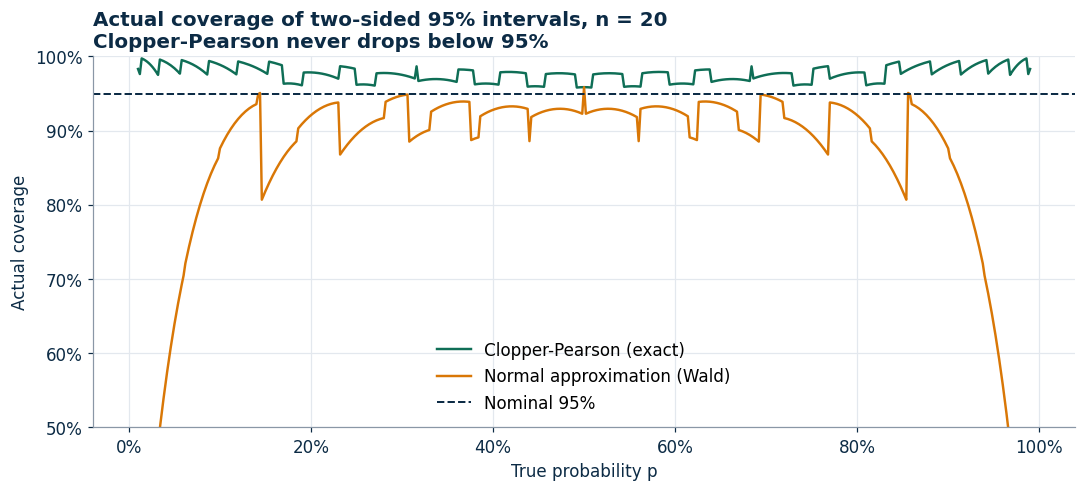

Clopper-Pearson: minimum coverage = 95.81%, average coverage = 97.68%
Wald:            minimum coverage = 18.21%, average coverage = 85.96%


In [ ]:
def exact_coverage(p, n, method):
    # Exact coverage probability of a two-sided 95% interval method at true probability p.
    k_all = np.arange(n + 1)
    if method == "clopper-pearson":
        bounds = [clopper_pearson(kk, n) for kk in k_all]
        lo = np.array([b["lower_2s"] for b in bounds])
        hi = np.array([b["upper_2s"] for b in bounds])
    elif method == "wald":
        ph = k_all / n
        half = 1.959964 * np.sqrt(ph * (1 - ph) / n)
        lo, hi = ph - half, ph + half
    covered = (lo <= p) & (p <= hi)
    return binom.pmf(k_all, n, p)[covered].sum()


n_cov = 20
p_cov = np.linspace(0.01, 0.99, 491)
cov_cp = np.array([exact_coverage(p, n_cov, "clopper-pearson") for p in p_cov])
cov_wald = np.array([exact_coverage(p, n_cov, "wald") for p in p_cov])

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(p_cov, cov_cp, color=TEAL, linewidth=1.6, label="Clopper-Pearson (exact)")
ax.plot(p_cov, cov_wald, color=AMBER, linewidth=1.6, label="Normal approximation (Wald)")
ax.axhline(0.95, color=NAVY, linestyle="--", linewidth=1.3, label="Nominal 95%")
ax.set_ylim(0.5, 1.0)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("True probability p")
ax.set_ylabel("Actual coverage")
ax.set_title(f"Actual coverage of two-sided 95% intervals, n = {n_cov}\nClopper-Pearson never drops below 95%", loc="left")
ax.legend(loc="lower center")
plt.tight_layout()
plt.show()

print(f"Clopper-Pearson: minimum coverage = {cov_cp.min():.2%}, average coverage = {cov_cp.mean():.2%}")
print(f"Wald:            minimum coverage = {cov_wald.min():.2%}, average coverage = {cov_wald.mean():.2%}")

Clopper-Pearson (teal) never drops below 95%. The normal approximation (amber) often falls well short, especially near 0% or 100%,
exactly where accuracy, sensitivity, and specificity tend to live. (For 9 of 10, it even gives an upper limit above 100%.)

---
# 7. Experiment with your own numbers

`explore(k, n)` prints and plots the results for any counts. If `ipywidgets` is installed, the following cell adds sliders.

9 successes out of 10 attempts
  Observed success rate     : 90.0%
  One-sided 95% lower bound : 60.6%
  Two-sided 95% CI          : 55.5% to 99.7%  (width 44.2%)


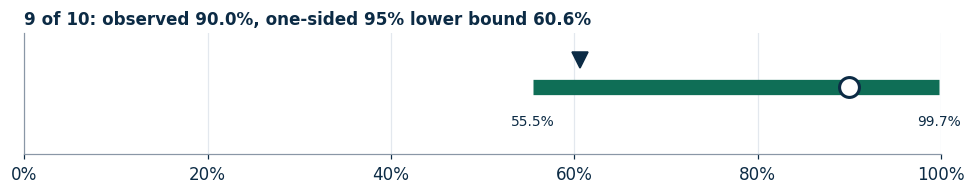

In [ ]:
def explore(k, n):
    # Print and plot the observed rate, the one-sided 95% lower bound, and the two-sided 95% CI for k of n.
    try:
        r = clopper_pearson(k, n)
    except (ValueError, TypeError) as err:
        print(f"Invalid input: {err}")
        return
    print(f"{k} successes out of {n} attempts")
    print(f"  Observed success rate     : {r['observed']:.1%}")
    print(f"  One-sided 95% lower bound : {r['lower_1s']:.1%}")
    print(f"  Two-sided 95% CI          : {r['lower_2s']:.1%} to {r['upper_2s']:.1%}"
          f"  (width {r['upper_2s'] - r['lower_2s']:.1%})")

    fig, ax = plt.subplots(figsize=(9, 1.9))
    ax.hlines(0, r["lower_2s"], r["upper_2s"], color=TEAL, linewidth=10, capstyle="butt")
    ax.plot(r["observed"], 0, "o", color="white", markeredgecolor=NAVY, markeredgewidth=2, markersize=13, zorder=3)
    ax.plot(r["lower_1s"], 0.3, "v", color=NAVY, markersize=11)
    ax.text(r["lower_2s"], -0.3, f"{r['lower_2s']:.1%}", ha="center", va="top", fontsize=9, color=NAVY)
    ax.text(r["upper_2s"], -0.3, f"{r['upper_2s']:.1%}", ha="center", va="top", fontsize=9, color=NAVY)
    ax.set_xlim(0, 1)
    ax.set_ylim(-0.75, 0.6)
    ax.set_yticks([])
    ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_title(f"{k} of {n}: observed {r['observed']:.1%}, one-sided 95% lower bound {r['lower_1s']:.1%}", loc="left", fontsize=11)
    plt.tight_layout()
    plt.show()


explore(9, 10)

In [ ]:
try:
    import ipywidgets as widgets
    from IPython.display import display

    n_slider = widgets.IntSlider(value=10, min=1, max=2000, step=1, description="n (attempts)",
                                 continuous_update=False, style={"description_width": "100px"}, layout={"width": "600px"})
    k_slider = widgets.IntSlider(value=9, min=0, max=10, step=1, description="k (successes)",
                                 continuous_update=False, style={"description_width": "100px"}, layout={"width": "600px"})

    def _sync_k_max(change):
        # Keep k within 0..n whenever n changes
        k_slider.max = change["new"]
        k_slider.value = min(k_slider.value, change["new"])

    n_slider.observe(_sync_k_max, names="value")
    display(widgets.interactive(explore, k=k_slider, n=n_slider))
except ImportError:
    print("ipywidgets is not installed, so the sliders are unavailable.")
    print("Call explore(k, n) with your own numbers instead, for example: explore(45, 50)")

interactive(children=(IntSlider(value=9, continuous_update=False, description='k (successes)', layout=Layout(w…

All of the examples so far, in one table:

In [ ]:
explore_cases = [
    ("9 / 10", 9, 10),
    ("90 / 100", 90, 100),
    ("900 / 1000", 900, 1000),
    ("Curry game 13 / 17", 13, 17),
    ("Curry season 324 / 789", 324, 789),
]
as_percent(cp_table(explore_cases))

,Successes (k),Attempts (n),Observed,One-sided 95% lower bound,Two-sided 95% CI lower,Two-sided 95% CI upper,Two-sided CI width
Case,,,,,,,
9 / 10,9,10,90.0%,60.6%,55.5%,99.7%,44.2%
90 / 100,90,100,90.0%,83.6%,82.4%,95.1%,12.7%
900 / 1000,900,1000,90.0%,88.3%,88.0%,91.8%,3.8%
Curry game 13 / 17,13,17,76.5%,53.9%,50.1%,93.2%,43.1%
Curry season 324 / 789,324,789,41.1%,38.1%,37.6%,44.6%,7.0%


---
# 8. From basketball to science

Basketball is just an intuitive **binomial experiment**. Scientists run the same kind of experiment whenever they report classification accuracy,
diagnostic sensitivity or specificity, detection rates, assay success rates, or screening hit rates.

Two papers each report an AI model with **95% accuracy**: one tested on **20 images**, the other on **10,000**.

,Successes (k),Attempts (n),Observed,One-sided 95% lower bound,Two-sided 95% CI lower,Two-sided 95% CI upper,Two-sided CI width
Case,,,,,,,
Paper A: 19 / 20 images,19,20,95.0%,78.4%,75.1%,99.9%,24.7%
"Paper B: 9,500 / 10,000 images",9500,10000,95.0%,94.6%,94.6%,95.4%,0.9%


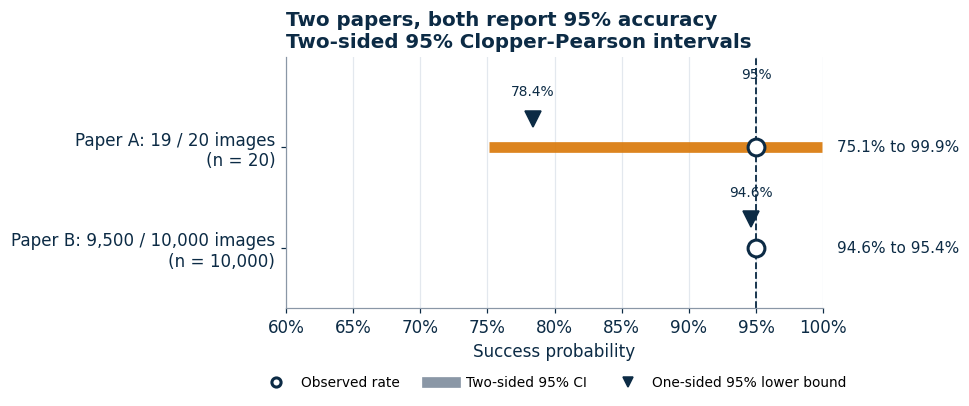

In [ ]:
ai_cases = [
    ("Paper A: 19 / 20 images", 19, 20),
    ("Paper B: 9,500 / 10,000 images", 9500, 10000),
]
ai_table = cp_table(ai_cases)
display(as_percent(ai_table))
plot_intervals(ai_table, [AMBER, TEAL], "Two papers, both report 95% accuracy\nTwo-sided 95% Clopper-Pearson intervals",
               xlim=(0.6, 1.0), ref_line=0.95, ref_label="95%")

Paper A's result is consistent with a model in the mid 70s. Paper B pins the accuracy down to within about half a percentage point.
**The percentage alone is incomplete.**

A practical planning question: with about 95% observed accuracy, how many test images are needed before the one-sided 95% lower bound clears a threshold?

In [ ]:
def smallest_n_for_lower_bound(observed_rate, threshold, n_max=5000):
    # Smallest test-set size n for which round(observed_rate * n) successes give a one-sided 95% lower bound >= threshold.
    for n in range(1, n_max + 1):
        k = int(round(observed_rate * n))
        if clopper_pearson(k, n)["lower_1s"] >= threshold:
            return n, k
    return None, None


for threshold in (0.85, 0.90, 0.93):
    n_req, k_req = smallest_n_for_lower_bound(0.95, threshold)
    print(f"Observed 95%: need about n = {n_req:>4} test images ({k_req} correct) for a lower bound >= {threshold:.0%}")

Observed 95%: need about n =   40 test images (38 correct) for a lower bound >= 85%
Observed 95%: need about n =   89 test images (85 correct) for a lower bound >= 90%
Observed 95%: need about n =  428 test images (407 correct) for a lower bound >= 93%


Demonstrating "at least 90%" takes close to a hundred test images, and the requirement grows quickly as the threshold approaches the observed rate.
This belongs in the **design** of a study, before data are collected.

---
# 9. A real example: malaria cell classification

## 9.1 The dataset

The **NIH malaria cell images dataset** (U.S. National Library of Medicine, LHNCBC) contains **27,558** segmented red blood cell images,
**13,779 parasitized** and **13,779 uninfected**, from Giemsa-stained thin blood smears of **150 *P. falciparum*-infected and 50 healthy patients**
(Chittagong Medical College Hospital, Bangladesh; annotated at the Mahidol-Oxford Tropical Medicine Research Unit).

- Download: https://data.lhncbc.nlm.nih.gov/public/Malaria/cell_images.zip (about 337 MB; folders `Parasitized/` and `Uninfected/`).
  Also available via TensorFlow Datasets (`malaria`) and Kaggle (`iarunava/cell-images-for-detecting-malaria`).
- Access: distributed openly by NLM and commonly listed as public domain; confirm current terms on the NLM page before redistributing.
- Citation: Rajaraman S, et al. *PeerJ* 6:e4568 (2018). https://doi.org/10.7717/peerj.4568 ; dataset page: https://lhncbc.nlm.nih.gov/publication/pub9932
- **Patients:** each filename begins with a patient token (for example `C33P1thinF_...`), which matches NLM's official patient mapping. We use it to keep all cells from one patient in the same split.

**Goal:** not a state-of-the-art detector, but an honest interpretation of an impressive-looking accuracy. So we use a simple, CPU-friendly model:
color and intensity features per cell plus a gradient-boosted tree classifier from scikit-learn. A CNN would score higher; the statistical lessons would be identical.

## 9.2 Locate (or download) the data

The next cell looks in `data/` (or `MALARIA_DATA_DIR`) and otherwise tries to download the archive. If the data cannot be found,
it prints instructions and **every later cell in this section skips cleanly**. Nothing is ever fabricated.

In [ ]:
import zipfile
import urllib.request

MALARIA_URL = "https://data.lhncbc.nlm.nih.gov/public/Malaria/cell_images.zip"
DATA_DIR = Path(os.environ.get("MALARIA_DATA_DIR", "data"))
AUTO_DOWNLOAD = True        # set to False if you prefer to download manually
EXPECTED_PER_CLASS = 13_779 # from the dataset documentation


def find_dataset_root(base):
    # Return the folder that directly contains 'Parasitized' and 'Uninfected' (searching recursively), or None.
    base = Path(base)
    if not base.exists():
        return None
    candidates = [base] + [p for p in base.rglob("*") if p.is_dir()]
    for c in candidates:
        if (c / "Parasitized").is_dir() and (c / "Uninfected").is_dir():
            if any((c / "Parasitized").glob("*.png")):
                return c
    return None


def download_malaria(dest_dir):
    # Download and extract the official archive. Returns True on success.
    dest_dir.mkdir(parents=True, exist_ok=True)
    zip_path = dest_dir / "cell_images.zip"
    try:
        if not zip_path.exists():
            print(f"Downloading {MALARIA_URL} (about 337 MB). This can take a few minutes...")
            urllib.request.urlretrieve(MALARIA_URL, zip_path)
        print("Extracting...")
        with zipfile.ZipFile(zip_path) as zf:
            zf.extractall(dest_dir)
        return True
    except Exception as err:   # network, SSL, proxy, or corrupt archive
        print(f"Download failed: {type(err).__name__}: {err}")
        if zip_path.exists() and not zipfile.is_zipfile(zip_path):
            zip_path.unlink()  # remove a partial download so the next attempt starts fresh
        return False


dataset_root = find_dataset_root(DATA_DIR)
if dataset_root is None and AUTO_DOWNLOAD:
    if download_malaria(DATA_DIR):
        dataset_root = find_dataset_root(DATA_DIR)

MALARIA_READY = dataset_root is not None
if MALARIA_READY:
    print(f"Dataset found at: {dataset_root.resolve()}")
else:
    print("The malaria dataset is not available, so Section 9 will be skipped.\n")
    print("To run it:")
    print(f"  1. Download {MALARIA_URL}")
    print(f"  2. Unzip it inside '{DATA_DIR.resolve()}' so that the folders")
    print("     .../Parasitized/*.png and .../Uninfected/*.png exist")
    print("  3. Re-run this cell and the cells below.")

Extracting...
Dataset found at: /content/data/cell_images


## 9.3 Index images, labels, and patients

Labels: **1 = Parasitized** (the positive class), **0 = Uninfected**. You should see 13,779 images per class and about 200 patient tokens.

In [ ]:
import re

PATIENT_PATTERN = re.compile(r"^(C\d+(?:P\d+)?)_?thin", re.IGNORECASE)


def patient_from_filename(name):
    # Extract the patient token from a filename such as 'C33P1thinF_IMG_..._cell_179.png' -> 'C33P1'.
    m = PATIENT_PATTERN.match(name)
    return m.group(1).upper() if m else name.split("_")[0].upper()


def build_index(root):
    records = []
    for class_name, label in (("Parasitized", 1), ("Uninfected", 0)):
        for path in sorted((root / class_name).glob("*.png")):
            records.append({"path": str(path), "class_name": class_name, "label": label,
                            "patient_id": patient_from_filename(path.name)})
    return pd.DataFrame(records)


if MALARIA_READY:
    index_df = build_index(dataset_root)
    counts = index_df["class_name"].value_counts()
    print("Images per class:")
    print(counts.to_string())
    print(f"Total images: {len(index_df):,}")
    print(f"Distinct patient tokens: {index_df['patient_id'].nunique()}")
    if any(counts.get(c, 0) != EXPECTED_PER_CLASS for c in ("Parasitized", "Uninfected")):
        print(f"\nNote: counts differ from the documented {EXPECTED_PER_CLASS:,} per class. "
              "Check that the download is complete and not a modified mirror.")
    per_patient = index_df.groupby("patient_id").size()
    print(f"Cells per patient: median {per_patient.median():.0f}, min {per_patient.min()}, max {per_patient.max()}")
else:
    print("Skipped: dataset not available.")

Images per class:
class_name
Parasitized    13779
Uninfected     13779
Total images: 27,558
Distinct patient tokens: 200
Cells per patient: median 86, min 65, max 702


## 9.4 Look at some cells

Parasitized cells show dark purple stained parasite material inside the pink cell; uninfected cells are more uniform, though some carry staining artifacts.

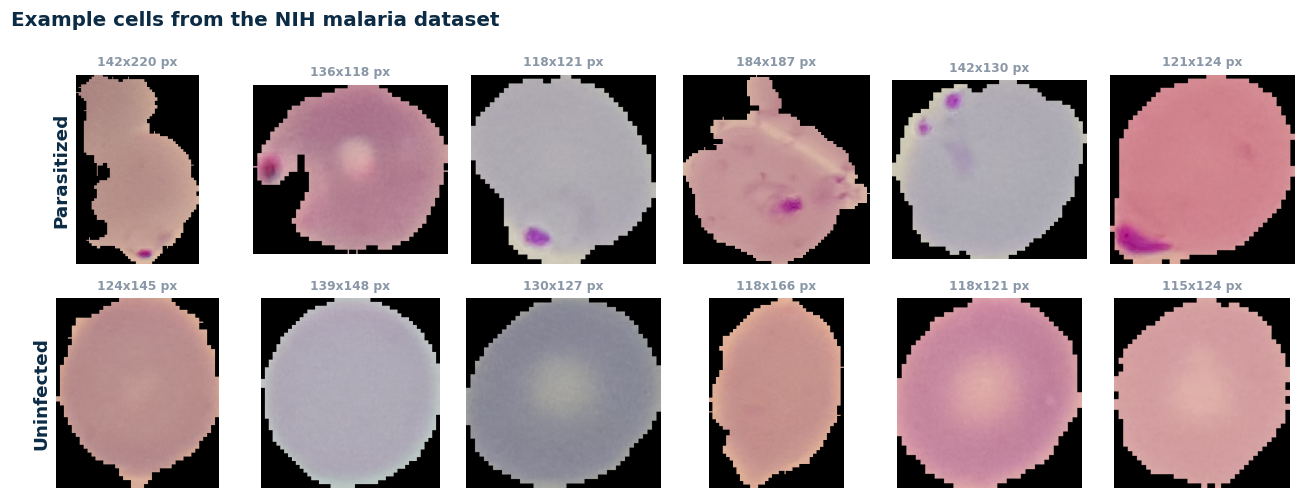

In [ ]:
from PIL import Image

if MALARIA_READY:
    n_show = 6
    example_rng = np.random.default_rng(SEED)
    fig, axes = plt.subplots(2, n_show, figsize=(2 * n_show, 4.6))
    for row_i, class_name in enumerate(("Parasitized", "Uninfected")):
        subset = index_df[index_df["class_name"] == class_name]
        picks = subset.iloc[example_rng.choice(len(subset), n_show, replace=False)]
        for col_i, (_, rec) in enumerate(picks.iterrows()):
            img = Image.open(rec["path"]).convert("RGB")
            ax = axes[row_i, col_i]
            ax.imshow(img)
            ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
            for spine in ax.spines.values():
                spine.set_visible(False)
            if col_i == 0:
                ax.set_ylabel(class_name, fontsize=12, color=NAVY, weight="bold")
            ax.set_title(f"{img.size[0]}x{img.size[1]} px", fontsize=8, color=GRAY)
    fig.suptitle("Example cells from the NIH malaria dataset", x=0.01, ha="left", fontsize=13, weight="bold", color=NAVY)
    plt.tight_layout()
    plt.show()
else:
    print("Skipped: dataset not available.")

## 9.5 Features

Each cell becomes a short vector: color histograms, intensity percentiles, and the fraction of unusually dark (parasite-stained) pixels, computed over the cell only.
Features are cached to disk, so only the first run takes a few minutes.

In [ ]:
IMG_SIZE = 64
FEATURE_CACHE = DATA_DIR / f"malaria_features_{IMG_SIZE}px.npz"


def extract_features(path):
    # Color and intensity features computed over the cell's foreground pixels.
    img = np.asarray(Image.open(path).convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR), dtype=np.float32) / 255.0
    gray = img.mean(axis=2)
    mask = gray > 0.05                       # background is (near) black
    if mask.sum() < 20:                      # degenerate segmentation: fall back to all pixels
        mask = np.ones_like(mask, dtype=bool)
    pixels = img[mask]                       # (num_foreground_pixels, 3)
    g = gray[mask]

    feats = []
    for c in range(3):                       # R, G, B histograms (normalized)
        hist, _ = np.histogram(pixels[:, c], bins=16, range=(0, 1))
        feats.extend(hist / hist.sum())
    for channel in (pixels[:, 0], pixels[:, 1], pixels[:, 2], g):
        feats.extend(np.percentile(channel, [1, 5, 10, 25, 50, 75]))
    median_g = np.median(g)
    for frac in (0.6, 0.7, 0.8, 0.9):        # share of pixels much darker than the cell's median brightness
        feats.append(np.mean(g < frac * median_g))
    feats.append(mask.mean())                # cell area fraction
    feats.append(g.std())
    return np.array(feats, dtype=np.float32)


def load_or_compute_features(df):
    if FEATURE_CACHE.exists():
        cached = np.load(FEATURE_CACHE, allow_pickle=False)
        if len(cached["paths"]) == len(df) and np.array_equal(cached["paths"], df["path"].values.astype(str)):
            print(f"Loaded cached features from {FEATURE_CACHE}")
            return cached["X"]
    X = np.zeros((len(df), len(extract_features(df["path"].iloc[0]))), dtype=np.float32)
    for i, p in enumerate(df["path"]):
        X[i] = extract_features(p)
        if (i + 1) % 2500 == 0 or i + 1 == len(df):
            print(f"  processed {i + 1:,} / {len(df):,} images")
    np.savez_compressed(FEATURE_CACHE, X=X, paths=df["path"].values.astype(str))
    return X


if MALARIA_READY:
    X_all = load_or_compute_features(index_df)
    y_all = index_df["label"].values
    groups_all = index_df["patient_id"].values
    print(f"Feature matrix: {X_all.shape[0]:,} images x {X_all.shape[1]} features")
else:
    print("Skipped: dataset not available.")

  processed 2,500 / 27,558 images
  processed 5,000 / 27,558 images
  processed 7,500 / 27,558 images
  processed 10,000 / 27,558 images
  processed 12,500 / 27,558 images
  processed 15,000 / 27,558 images
  processed 17,500 / 27,558 images
  processed 20,000 / 27,558 images
  processed 22,500 / 27,558 images
  processed 25,000 / 27,558 images
  processed 27,500 / 27,558 images
  processed 27,558 / 27,558 images
Feature matrix: 27,558 images x 78 features


## 9.6 Split by patient: train, validation, test

- **Train (about 64%)** fits the model; **validation (about 16%)** chooses between a few settings; **test (about 20%)** is locked away and used **once**.
- We split **by patient** with `GroupShuffleSplit` and assert that no patient appears in two sets. A random image-level split would let the model recognize a patient's slide rather than the parasite.

In [ ]:
from sklearn.model_selection import GroupShuffleSplit, train_test_split

if MALARIA_READY:
    n_groups = len(np.unique(groups_all))
    use_groups = 10 <= n_groups < len(groups_all)   # sanity check that patient parsing worked

    if use_groups:
        outer = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
        trainval_idx, test_idx = next(outer.split(X_all, y_all, groups_all))
        inner = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
        tr_rel, va_rel = next(inner.split(X_all[trainval_idx], y_all[trainval_idx], groups_all[trainval_idx]))
        train_idx, val_idx = trainval_idx[tr_rel], trainval_idx[va_rel]
        g_tr, g_va, g_te = (set(groups_all[i]) for i in (train_idx, val_idx, test_idx))
        assert not (g_tr & g_va) and not (g_tr & g_te) and not (g_va & g_te), "Patient leakage between splits!"
        print("Patient-level split: no patient appears in more than one set.")
    else:
        print("WARNING: patient tokens could not be parsed reliably. Falling back to an image-level stratified split.")
        print("         Results will NOT be patient-independent; treat them as optimistic.")
        all_idx = np.arange(len(y_all))
        trainval_idx, test_idx = train_test_split(all_idx, test_size=0.20, stratify=y_all, random_state=SEED)
        train_idx, val_idx = train_test_split(trainval_idx, test_size=0.20, stratify=y_all[trainval_idx], random_state=SEED)

    split_summary = pd.DataFrame({
        "Images": [len(train_idx), len(val_idx), len(test_idx)],
        "Patients": [len(np.unique(groups_all[i])) for i in (train_idx, val_idx, test_idx)],
        "Parasitized": [int(y_all[i].sum()) for i in (train_idx, val_idx, test_idx)],
        "Uninfected": [int((1 - y_all[i]).sum()) for i in (train_idx, val_idx, test_idx)],
    }, index=["Train", "Validation", "Test"])
    display(split_summary)
else:
    print("Skipped: dataset not available.")

Patient-level split: no patient appears in more than one set.


,Images,Patients,Parasitized,Uninfected
Train,17482,128,8619,8863
Validation,5471,32,3284,2187
Test,4605,40,1876,2729


## 9.7 Train, selecting settings on validation data only

We try three settings, keep the best by **validation** accuracy, and refit it on train plus validation. The test set is not touched.

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

CANDIDATE_SETTINGS = [
    {"learning_rate": 0.05, "max_leaf_nodes": 15},
    {"learning_rate": 0.10, "max_leaf_nodes": 31},
    {"learning_rate": 0.10, "max_leaf_nodes": 63},
]


def make_model(settings):
    return HistGradientBoostingClassifier(max_iter=300, random_state=SEED, **settings)


if MALARIA_READY:
    val_results = []
    for settings in CANDIDATE_SETTINGS:
        model = make_model(settings).fit(X_all[train_idx], y_all[train_idx])
        val_acc = accuracy_score(y_all[val_idx], model.predict(X_all[val_idx]))
        val_results.append({**settings, "validation_accuracy": val_acc})
    val_df = pd.DataFrame(val_results)
    display(val_df.style.format({"validation_accuracy": "{:.2%}"}))

    best_settings = CANDIDATE_SETTINGS[int(val_df["validation_accuracy"].idxmax())]
    print(f"Selected on validation data: {best_settings}")

    # Final model: refit the chosen setting on train + validation. The test set is still untouched.
    final_model = make_model(best_settings).fit(X_all[trainval_idx], y_all[trainval_idx])
    print("Final model trained.")
else:
    print("Skipped: dataset not available.")

,learning_rate,max_leaf_nodes,validation_accuracy
0,0.050000,15,93.04%
1,0.100000,31,93.15%
2,0.100000,63,92.91%


Selected on validation data: {'learning_rate': 0.1, 'max_leaf_nodes': 31}
Final model trained.


## 9.8 Evaluate once on the test set

With **Parasitized** as the positive class: TP = infected and caught, FN = infected but missed, FP = false alarm, TN = healthy and cleared.

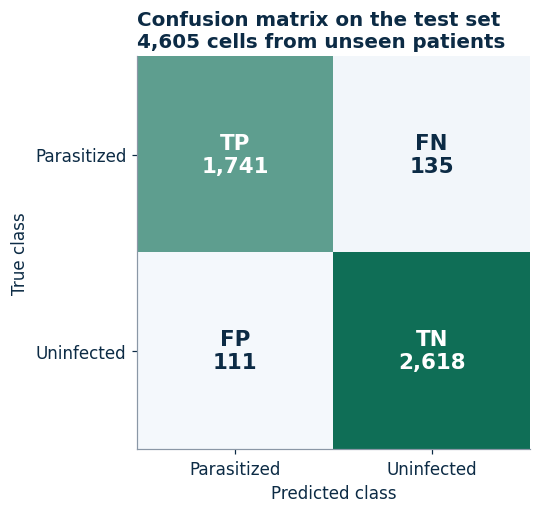

TP = 1,741   FN = 135   FP = 111   TN = 2,618   total = 4,605


In [ ]:
if MALARIA_READY:
    y_test = y_all[test_idx]
    y_pred = final_model.predict(X_all[test_idx])

    # labels=[1, 0] puts Parasitized (positive) first
    cm = confusion_matrix(y_test, y_pred, labels=[1, 0])
    TP, FN, FP, TN = int(cm[0, 0]), int(cm[0, 1]), int(cm[1, 0]), int(cm[1, 1])

    fig, ax = plt.subplots(figsize=(5.6, 4.8))
    ax.imshow(cm, cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list("teal", ["#F4F8FC", TEAL]))
    names = [["TP", "FN"], ["FP", "TN"]]
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{names[i][j]}\n{cm[i, j]:,}", ha="center", va="center", fontsize=14,
                    color="white" if cm[i, j] > cm.max() / 2 else NAVY, weight="bold")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Parasitized", "Uninfected"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Parasitized", "Uninfected"])
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
    ax.grid(False)
    ax.set_title(f"Confusion matrix on the test set\n{len(y_test):,} cells from unseen patients", loc="left")
    plt.tight_layout()
    plt.show()
    print(f"TP = {TP:,}   FN = {FN:,}   FP = {FP:,}   TN = {TN:,}   total = {TP + FN + FP + TN:,}")
else:
    print("Skipped: dataset not available.")

## 9.9 Accuracy, sensitivity, and specificity with Clopper-Pearson bounds

Each metric is a binomial proportion with its **own denominator**:

| Metric | $k$ | $n$ |
|---|---|---|
| Accuracy | TP + TN | all test cells |
| Sensitivity (parasitized) | TP | TP + FN |
| Specificity (uninfected) | TN | TN + FP |

,Successes (k),Attempts (n),Observed,One-sided 95% lower bound,Two-sided 95% CI lower,Two-sided 95% CI upper,Two-sided CI width
Case,,,,,,,
Accuracy,4359,4605,94.7%,94.1%,94.0%,95.3%,1.3%
Sensitivity (parasitized),1741,1876,92.8%,91.7%,91.5%,93.9%,2.4%
Specificity (uninfected),2618,2729,95.9%,95.3%,95.1%,96.6%,1.5%


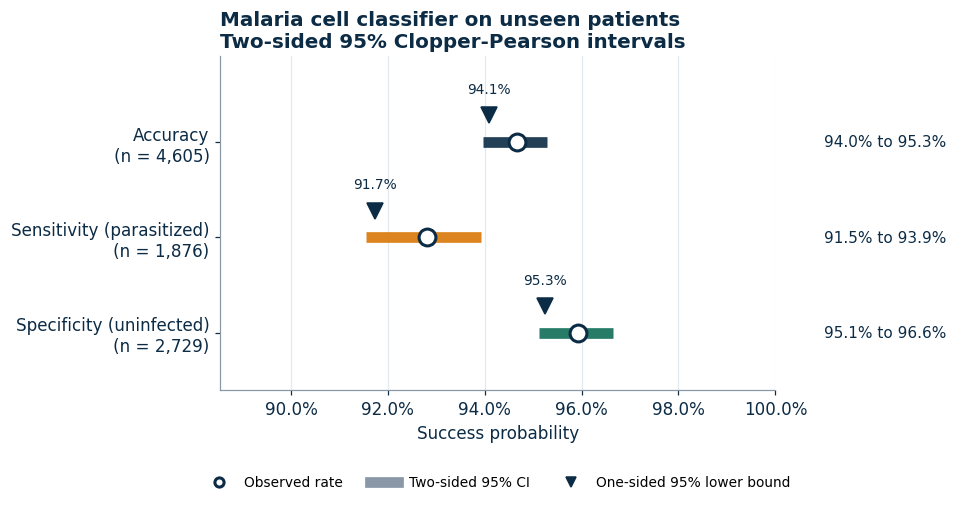

In [ ]:
if MALARIA_READY:
    metric_cases = [
        ("Accuracy", TP + TN, TP + TN + FP + FN),
        ("Sensitivity (parasitized)", TP, TP + FN),
        ("Specificity (uninfected)", TN, TN + FP),
    ]
    malaria_table = cp_table(metric_cases)
    display(as_percent(malaria_table))

    lo_x = max(0.0, malaria_table["Two-sided 95% CI lower"].min() - 0.03)
    plot_intervals(malaria_table, [NAVY, AMBER, TEAL],
                   "Malaria cell classifier on unseen patients\nTwo-sided 95% Clopper-Pearson intervals",
                   xlim=(lo_x, 1.0))
else:
    print("Skipped: dataset not available.")

With thousands of test cells, all three intervals are narrow. Compare the rows: **overall accuracy can hide class-specific differences.**
If sensitivity is lower than specificity, the model misses infected cells more often than it raises false alarms, which matters most in screening.

The summary sentence is written directly from the computed numbers:

In [ ]:
if MALARIA_READY:
    acc = malaria_table.loc["Accuracy"]
    sens = malaria_table.loc["Sensitivity (parasitized)"]
    spec = malaria_table.loc["Specificity (uninfected)"]
    n_test_patients = len(np.unique(groups_all[test_idx]))
    print(
        f"Our classifier achieved {acc['Observed']:.1%} accuracy on {int(acc['Attempts (n)']):,} previously unseen cell images "
        f"from {n_test_patients} held-out patients.\n"
        f"The one-sided 95% lower confidence bound is {acc['One-sided 95% lower bound']:.1%} "
        f"(two-sided 95% CI: {acc['Two-sided 95% CI lower']:.1%} to {acc['Two-sided 95% CI upper']:.1%}).\n"
        f"Sensitivity was {sens['Observed']:.1%} (one-sided 95% lower bound {sens['One-sided 95% lower bound']:.1%}, "
        f"n = {int(sens['Attempts (n)']):,} parasitized cells) and specificity was {spec['Observed']:.1%} "
        f"(one-sided 95% lower bound {spec['One-sided 95% lower bound']:.1%}, n = {int(spec['Attempts (n)']):,} uninfected cells)."
    )
else:
    print("Skipped: dataset not available.")

Our classifier achieved 94.7% accuracy on 4,605 previously unseen cell images from 40 held-out patients.
The one-sided 95% lower confidence bound is 94.1% (two-sided 95% CI: 94.0% to 95.3%).
Sensitivity was 92.8% (one-sided 95% lower bound 91.7%, n = 1,876 parasitized cells) and specificity was 95.9% (one-sided 95% lower bound 95.3%, n = 2,729 uninfected cells).


## 9.10 What the interval does and does not tell us

**What it means.** The Clopper-Pearson bound quantifies **sampling uncertainty**: how much the measured accuracy depends on which cells landed in the test set,
assuming test cells are independent draws from one population. The one-sided lower bound is a conservative figure for **measured** performance on this kind of data.

**Independence caveat.** Our test cells come from a limited number of patients, and cells from one slide share staining, focus, and biology.
Treating every cell as independent **overstates the effective sample size**, so the real uncertainty is larger than the interval suggests.
The honest effective $n$ lies somewhere between the number of test **patients** and the number of test **cells**.

**What it does not account for:** dataset bias (one hospital, one protocol), distribution shift (other microscopes, stains, species),
label quality (an independent review relabeled a sizable share of this dataset), and the gap between curated research data and real clinical slides.
This model also classifies **pre-segmented cells**; diagnosing a **patient** is a different task.

> **A narrow confidence interval does not mean a model is clinically reliable.** It means we measured its performance on **this** test set precisely.

---
# 10. Takeaways

1. **An observed percentage is not necessarily the true underlying probability.** 9 of 10 is consistent with a 75% shooter.
2. **Sample size matters.** The uncertainty shrinks roughly with $1/\sqrt{n}$.
3. **Identical percentages can carry very different evidence.** 9/10, 90/100, and 900/1000 are all 90%, with very different intervals.
4. **Clopper-Pearson is an exact binomial interval.** Built directly from the binomial distribution, computed with the beta quantile function, and guaranteed to cover at least 95%.
5. **A one-sided lower bound is the right tool for a conservative minimum.** It is not the same as the lower end of a two-sided interval.
6. **In research, reporting accuracy without sample size and uncertainty can mislead.** Always report $k$, $n$, and an interval.
7. **Confidence intervals do not fix bad data.** They do not address dataset bias, label errors, dependence, or lack of external validation.

## Don't just report the percentage. Report how much evidence supports it.

---
### References

- Clopper CJ, Pearson ES. The use of confidence or fiducial limits illustrated in the case of the binomial. *Biometrika* 26(4):404-413 (1934). https://doi.org/10.1093/biomet/26.4.404
- Rajaraman S, et al. Pre-trained convolutional neural networks as feature extractors toward improved malaria parasite detection in thin blood smear images. *PeerJ* 6:e4568 (2018). https://doi.org/10.7717/peerj.4568
- NLM LHNCBC malaria datasets: https://lhncbc.nlm.nih.gov/publication/pub9932 ; archive: https://data.lhncbc.nlm.nih.gov/public/Malaria/cell_images.zip
- TensorFlow Datasets, `malaria`: https://www.tensorflow.org/datasets/catalog/malaria
- Patient mapping cross-check of filename tokens: EMFE, arXiv:2608.24793. https://arxiv.org/abs/2608.24793
- Relabeled version of the dataset: Chakradeo K, Delves M. Malaria dataset (thin blood smear, updated). IEEE DataPort. https://ieee-dataport.org/open-access/malaria-dataset-thin-blood-smear-updated
- Curry statistics: NBA.com (Warriors), AP, Sports Illustrated, StatMuse, and Land of Basketball (full URLs in Section 3.1).
- SciPy documentation, `scipy.stats.beta`: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.beta.html